In [18]:
import pandas as pd
kenyacropsData = pd.read_csv('kenya_crops_Dataset.csv')
kenyacropsData.head()

,Farmer Name,County,Crop Type,Crop Variety,Season,Planted Area (Acres),Yield (Kg),Market Price (KES/Kg),Revenue (KES),Cost of Production (KES),Profit (KES),Planting Date,Harvest Date,Soil Type,Irrigation Method,Fertilizer Used,Pest Control,Weather Impact,Farmer Contact,Notes
0,Farmer 1,Kiambu,Potatoes,Organic,Long Rains,15.14,1654.76,100.19,2510066.72,8977.19,2501089.53,2023-08-01,2023-11-02,Peaty,Drip,NaN,Organic,Mild,0731810617,High yield
1,Farmer 2,Meru,Coffee,Local,Short Rains,13.54,1957.61,168.63,4469713.42,47882.55,4421830.87,2023-02-25,2023-09-07,Silty,Sprinkler,Error,Organic,Mild,0773993471,NaN
2,Farmer 3,Nakuru,Sorghum,Error,Long Rains,19.33,4679.65,102.63,9283667.03,69370.32,9214296.71,2023-07-08,2023-12-28,Peaty,NaN,CAN,NaN,NaN,0778642041,Delayed harvest
3,Farmer 4,Eldoret,Potatoes,Organic,Short Rains,1.56,420.18,125.2,82066.20,43454.15,38612.05,2023-03-22,2024-01-08,NaN,NaN,UREA,Chemical,Mild,0758586340,NaN
4,Farmer 5,Machakos,Tomatoes,Hybrid,Short Rains,13.93,Error,199.42,NaN,69673.69,NaN,2023-03-01,2023-10-24,Clay,NaN,UREA,NaN,Severe,0770291817,NaN


In [16]:
kenyacropsData.columns

Index(['Farmer Name', 'County', 'Crop Type', 'Crop Variety', 'Season',
       'Planted Area (Acres)', 'Yield (Kg)', 'Market Price (KES/Kg)',
       'Revenue (KES)', 'Cost of Production (KES)', 'Profit (KES)',
       'Planting Date', 'Harvest Date', 'Soil Type', 'Irrigation Method',
       'Fertilizer Used', 'Pest Control', 'Weather Impact', 'Farmer Contact',
       'Notes'],
      dtype='str')

In [17]:
kenyacropsData.info() 

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Farmer Name               500 non-null    str    
 1   County                    460 non-null    str    
 2   Crop Type                 463 non-null    str    
 3   Crop Variety              469 non-null    str    
 4   Season                    470 non-null    str    
 5   Planted Area (Acres)      489 non-null    str    
 6   Yield (Kg)                482 non-null    str    
 7   Market Price (KES/Kg)     483 non-null    str    
 8   Revenue (KES)             429 non-null    float64
 9   Cost of Production (KES)  481 non-null    str    
 10  Profit (KES)              404 non-null    float64
 11  Planting Date             483 non-null    str    
 12  Harvest Date              490 non-null    str    
 13  Soil Type                 471 non-null    str    
 14  Irrigation Method    

In [4]:
import numpy as np
import matplotlib as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [5]:
import numpy as np
n_samples = 100
sizes = np.random.randint(800, 3000, n_samples)
sizes

array([1180, 1412, 2181, 2054, 1847, 1267, 1320, 2596, 1760, 2079, 2016,
       2817, 1128, 2102, 1996, 1367, 2190, 1909, 1432, 1284,  873,  996,
       1326, 1012, 1387, 1398, 1851, 1347, 2548, 1594,  866, 2162, 2732,
       1483, 1443,  827, 2548, 1322, 1694, 2978, 1775, 1909, 2722, 2730,
       1768, 2338, 1690, 2129, 1810, 1570, 2940, 2435, 1395, 2004, 2770,
       2993, 1793, 1285, 2068, 2451, 1132, 1439, 2420, 1479, 2865, 1830,
        967, 2645, 2806, 2423, 2002,  897,  845, 2205, 2525, 2159,  991,
       1927, 2957, 1750,  956, 2485, 2492, 1894, 2828, 1546, 2072,  998,
       1237, 1739, 2792, 2653, 2311, 2393, 1205, 2936, 2130, 2565, 2489,
       1127], dtype=int32)

In [6]:
prices = 200 * sizes + np.random.normal(0, 50000, n_samples)
prices

array([286570.54411497, 275427.08154715, 464941.491392  , 474403.08630448,
       263562.35925592, 274151.06773191, 289775.63156651, 510282.00724051,
       363802.48259036, 342424.96266425, 441068.0003805 , 622079.20533238,
       245944.22539381, 452847.90843638, 477100.27010488, 312708.70596523,
       459057.11045414, 373122.06018995, 265811.67955376, 276363.0757095 ,
       132863.61792718, 176699.10235048, 247198.56326929, 230013.65333832,
       192069.45063822, 321458.66224523, 419553.92910266, 337383.79329597,
       561283.96645953, 279714.43827298, 219232.5076612 , 435440.44365939,
       619864.24753234, 273842.56151659, 293724.25843568, 149401.1449404 ,
       664377.5584687 , 264417.38533452, 348821.46166509, 547826.5023948 ,
       331331.74807619, 372195.35559247, 513050.58980633, 570513.57591018,
       335808.00662816, 388402.16146856, 320775.98926336, 419432.01180179,
       323843.65979708, 431411.43888523, 583655.65362604, 471783.86894414,
       239691.09275059, 3

In [7]:
df = pd.DataFrame({'Size': sizes, 'Price': prices})
df.head()

,Size,Price
0,1180,286570.544115
1,1412,275427.081547
2,2181,464941.491392
3,2054,474403.086304
4,1847,263562.359256


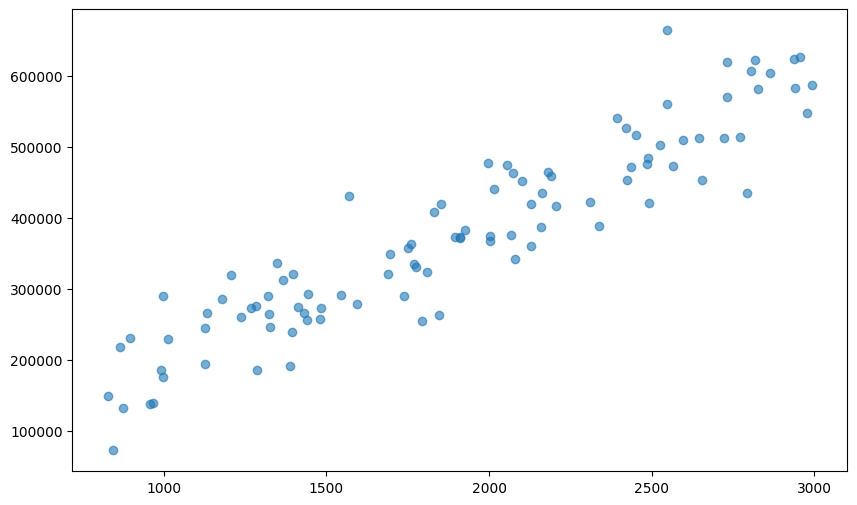

In [15]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(10,6))
plt.scatter(df['Size'], df['Price'], alpha=0.6)

In [ ]:
# split the data into training and testing sets
# features (X) and target variable (y)
x = df[['Size']]
y= df['Price']

# x = spillting data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f'Training samples: {len(x_train)}')
print(f'Testing samples: {len(x_test)}')

In [ ]:
# create the model
model = LinearRegression()

model.fit(x_train, y_train) 
print('Model trained successfully.')

Model trained successfully.


In [ ]:
print(f'Learned formula: Price = {model.coef_[0]:.2f} * Size + {model.intercept_:.2f}')

Learned formula: Price = 216.19 * Size + -38318.75


In [ ]:
# Evaluating performance
y_pred = model.predict(x_test)
mse = mean_squared_error(y_test, y_pred)

In [ ]:
# create sample Data
np.random.seed(42)

n_samples = 100
sizes = np.random.randint(800, 3000, n_samples)
# price = 200 * size + random_noise
prices = 200 * sizes + np.random.normal(0, 5000, n_samples)

df=pd.DataFrame({
    'size': sizes,
    'price': prices
            })

print(df.head())
print()
df

   size          price
0  1660  331247.330709
1  2094  413972.211641
2  1930  386752.445391
3  1895  378432.893743
4  2438  500767.641103



,size,price
0,1660,331247.330709
1,2094,413972.211641
2,1930,386752.445391
3,1895,378432.893743
4,2438,500767.641103
...,...,...
95,1197,229727.149022
96,1670,334753.295217
97,1192,238321.425301
98,1006,194549.629672


In [ ]:
rmse = np.sqrt(mse)
rmse

np.float64(70221.99228965788)

### r2 score.
A statistical measure indicating how well independent variables explain the variance

In [ ]:
r2 = r2_score(y_test, y_pred)
r2

0.7577187156561571

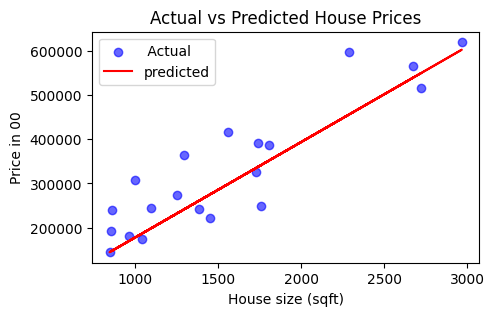

In [ ]:
# Visualization

plt.figure(figsize=(5,3))

plt.scatter(x_test, y_test, color = 'blue', alpha = 0.6, label = ' Actual')

plt.plot(x_test, y_pred, color ='red', label='predicted')

plt.xlabel('House size (sqft)')
plt.ylabel('Price in 00')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.show()


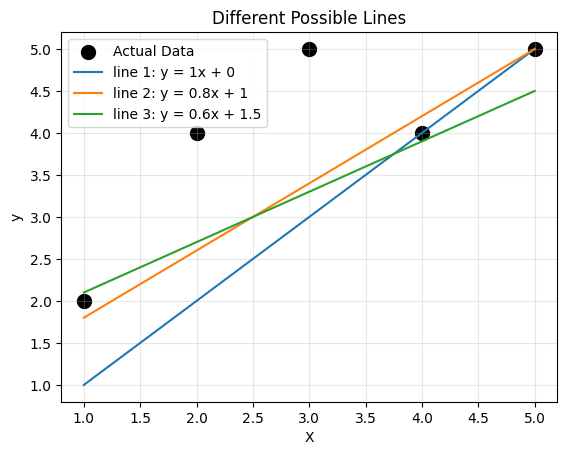

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# create data

X = np.array([1, 2, 3, 4, 5])
y_actual = np.array([2, 4, 5, 4, 5])

# different lines'
def plot_line(slope, intercept, label):
    y_pred = slope * X + intercept
    plt.plot(X, y_pred, label = f'{label}: y = {slope}x + {intercept}')

# plot data points
plt.scatter(X , y_actual, color = 'black', s=100, label = 'Actual Data')

# try different lines y = mx + c
plot_line(1, 0, 'line 1')
plot_line(0.8, 1, 'line 2')
plot_line(0.6, 1.5, 'line 3')

plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.title('Different Possible Lines')
plt.grid(True, alpha = 0.3)
plt.show()

# Cost function and gradient descent
### Cost function  (MSE)
measures how wrong our model is.
 MSE = (1/N) * summation(actual - predicted)^ 2

 ### Why we square 
 - makes all errors positive
 - penalize large errors more
 - mathematically covenient

In [ ]:
actual = [100, 200, 300]
predicted =[110, 190, 290]

# errors = [-10, 10, 10]
mse =((-10)**2 + 10**2 + 10**2)
mse = mse/3
mse

100.0

# R2 score (coefficient of Determination)
R2 = 1 - (sum of squared residuals / total sum of squares)
Range: 0 - 1 (can be negative if model is terrible)

-1.0 = perfect fit
-0.9 = excellent
-0.7 - 0.9 = good
-0.5 -0.7 = moderate
<0.5 = poor.

In [ ]:
actual = [100, 200, 300]
predicted = [110, 190, 290]

# r2 = 1 - ssr/sst
# ssr = summation (y_actual - y_mean) ** 2
y_mean = (100+200+300)/3
sst = (100 - y_mean) ** 2 + (200- y_mean) ** 2 + (300 - y_mean) ** 2

# ssr = summation (y_actual - y_predicted) ** 2
ssr = (100 -110) **2 + (200 -190) ** 2 + (300 - 290) **2

r2 = 1 - (ssr/sst)
r2

0.985

In [ ]:
from sklearn.metrics import r2_score
r2_2 = r2_score(actual, predicted)
r2_2

0.985

# How linear regression finds the best line
## Gradient descent ( The learning algorithim)
```y = mX + c``` -> X is the input, y - dependent variable/ label
1. Start with random slope and intercept
2. Calculate the error (mse)
3. Adjust slope intercept to reduce error
4. Repeat until error stops decreasing
5 Found the best line

## Parameters
### learning rate -> How big are the steps?
- Too small - Takes forever
- Too large - Might overshoot
-Just right - converges efficiently


```from sklearn.linear_model import LinearRegression``
```model = LinearRegression()```
```model.fit(x_train, y_train) # gradient descent ```

## Second Regression Model

In [18]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
import pandas as pd
import sklearn.model_selection as  train_test_split

#load the california housing dataset
data = fetch_california_housing()

df = pd.DataFrame(data.data, columns=data.feature_names)
df['price'] = data.target

In [19]:
# prepare the data
print(df.head())    
df.info()

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  price  
0    -122.23  4.526  
1    -122.22  3.585  
2    -122.24  3.521  
3    -122.25  3.413  
4    -122.25  3.422  
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-

In [22]:
# step 3 features and target variable
X = df.drop('price', axis = 1)
y = df['price']

#splitting Data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [23]:
# model training
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [24]:
# Making predictions on the test data 
y_predict = model.predict(X_test)   

In [26]:
# Evaluate performance
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_predict)

rmse= np.sqrt(mse)
r2 = r2_score(y_test, y_predict)
print(f'Mean Squared Error: {mse:.2f}')
print(f'Root Mean Squared Error: {rmse:.2f}')   
print(f'R-squared: {r2:.2f}')

Mean Squared Error: 0.52
Root Mean Squared Error: 0.72
R-squared: 0.61
